# Практическая работа 6 Кластеризация
Албахтин И.В., ИНБО-12-23. Набор Dry Bean, 13 611 объектов, 16 морфологических признаков. Метка Class исключается из признаков и используется только для внешнего описания уже полученного разбиения. Все три алгоритма обучаются на полном наборе; выборка используется только для дорогой оценки силуэта.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib,json,platform,os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,DBSCAN
from sklearn.metrics import silhouette_score,adjusted_rand_score,normalized_mutual_info_score
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage,fcluster,dendrogram
import joblib
SEED=42
ROOT=Path.cwd();OUT=ROOT/'results/pr6';OUT.mkdir(parents=True,exist_ok=True)
MODELS=ROOT/'models/pr6';MODELS.mkdir(parents=True,exist_ok=True)
data_path=ROOT/'data/Dry_Bean.csv'
raw=pd.read_csv(data_path);features=[c for c in raw.columns if c!='Class']
assert raw.shape==(13611,17) and not raw.isna().any().any()
assert len(features)==16 and 'Class' not in features
print(raw.shape,raw['Class'].value_counts().to_dict())
quality={'nulls':raw.isna().sum().to_dict(),'duplicate_feature_rows':int(raw.duplicated(features).sum()),'rows':len(raw),'features':features}

(13611, 17) {'DERMASON': 3546, 'SIRA': 2636, 'SEKER': 2027, 'HOROZ': 1928, 'CALI': 1630, 'BARBUNYA': 1322, 'BOMBAY': 522}


## 1 Масштабирование и фиксированная выборка оценки
StandardScaler обучается на всей неразмеченной выборке, поскольку задача описательная и отдельного прогноза на новых объектах здесь нет. Повторяющиеся векторы сохранены: источник не содержит идентификаторов, позволяющих доказать, что это ошибочные дубликаты. Для всех алгоритмов используется одна фиксированная выборка оценки; истинные классы не влияют на подбор.

In [2]:
X_raw=raw[features].to_numpy(dtype=float)
scaler=StandardScaler();X=scaler.fit_transform(X_raw)
sample=np.sort(np.random.default_rng(SEED).choice(len(X),size=4000,replace=False))
assert np.allclose(X.mean(axis=0),0,atol=1e-9)
def sil(labels):
    keep=labels[sample]>=0;lab=labels[sample][keep]
    if len(set(lab))<2 or len(set(lab))>=len(lab):return None
    return float(silhouette_score(X[sample][keep],lab,metric='euclidean'))
pd.DataFrame({'feature':features,'original_std':X_raw.std(axis=0),'scaled_std':X.std(axis=0)}).to_csv(OUT/'scaling.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].boxplot(X_raw[:,:6],tick_labels=features[:6]);axes[0].tick_params(axis='x',rotation=60);axes[0].set(title='Исходные масштабы')
axes[1].boxplot(X[:,:6],tick_labels=features[:6]);axes[1].tick_params(axis='x',rotation=60);axes[1].set(title='После StandardScaler');fig.tight_layout();fig.savefig(OUT/'scaling.png',dpi=160);plt.show();plt.close(fig)

## 2 KMeans и выбор числа кластеров
Для k от 2 до 10 сохраняются inertia, силуэт и размеры групп. Критерий выбора — максимальный силуэт; график локтя служит отдельной проверкой геометрии. Наличие семи исходных классов не используется как основание установить k=7.

In [3]:
k_models={};k_rows=[]
for k in range(2,11):
    start=perf_counter();model=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(X)
    k_models[k]=model
    sizes=np.bincount(model.labels_,minlength=k)
    k_rows.append({'k':k,'inertia':float(model.inertia_),'silhouette':sil(model.labels_),'fit_s':perf_counter()-start,'min_cluster':int(sizes.min()),'max_cluster':int(sizes.max())})
k_table=pd.DataFrame(k_rows);BEST_K=int(k_table.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]['k']);km=k_models[BEST_K]
k_table.to_csv(OUT/'kmeans_selection.csv',index=False);print(k_table.to_string(index=False));print('Selected k',BEST_K)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(k_table.k,k_table.inertia,'o-');axes[0].set(xlabel='k',ylabel='Inertia',title='Правило локтя');axes[1].plot(k_table.k,k_table.silhouette,'o-');axes[1].set(xlabel='k',ylabel='Silhouette',title='Евклидов силуэт');fig.tight_layout();fig.savefig(OUT/'kmeans_selection.png',dpi=160);plt.show();plt.close(fig)

 k       inertia  silhouette    fit_s  min_cluster  max_cluster
 2 129900.033952    0.399590 1.215614         5580         8031
 3  94741.986546    0.408709 1.414911          524         7579
 4  76474.309201    0.345569 1.041807          524         5874
 5  61893.623324    0.361451 0.995442          521         5858
 6  55050.069655    0.365018 1.483410          520         5804
 7  48811.954795    0.316523 1.416766          520         3157
 8  45241.638025    0.312396 1.354954          452         3164
 9  41975.594824    0.312101 1.572214          438         3140
10  39771.199925    0.293390 1.471719          434         2624
Selected k 3


## 3 Иерархическая кластеризация полного набора
Метод Уорда минимизирует прирост внутрикластерной суммы квадратов. Дерево строится один раз для всех 13 611 объектов. Срез использует то же k, выбранное без истинных меток; дендрограмма сокращена только при отображении, не при обучении.

In [4]:
start=perf_counter();tree=linkage(X,method='ward',metric='euclidean');hier_s=perf_counter()-start
hier=fcluster(tree,t=BEST_K,criterion='maxclust')-1
assert len(hier)==len(raw) and tree.shape==(len(raw)-1,4)
pd.DataFrame(tree,columns=['left','right','distance','objects']).to_csv(OUT/'hierarchy_linkage.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5));dendrogram(tree,truncate_mode='lastp',p=30,show_leaf_counts=True,ax=ax);ax.set(title='Ward: последние 30 объединений полного дерева',xlabel='Группы объектов',ylabel='Расстояние слияния');fig.tight_layout();fig.savefig(OUT/'dendrogram.png',dpi=160);plt.show();plt.close(fig)

## 4 DBSCAN
eps подбирается в стандартизованном 16-мерном пространстве. Силуэт считается без шума, поэтому одновременно сохраняется доля покрытых объектов. Для выбора требуются не менее двух кластеров и покрытие не ниже 80 процентов; шум не выдаётся за отдельный содержательный кластер.

In [5]:
neighbors=NearestNeighbors(n_neighbors=10,n_jobs=2).fit(X)
dist,_=neighbors.kneighbors(X)
fig,ax=plt.subplots(figsize=(8,4));ax.plot(np.sort(dist[:,-1]));ax.set(xlabel='Объекты в порядке расстояния',ylabel='Расстояние до 10-го соседа',title='Диагностика плотности для DBSCAN');fig.tight_layout();fig.savefig(OUT/'dbscan_neighbors.png',dpi=160);plt.show();plt.close(fig)
db_models={};db_rows=[]
for eps in [.5,.7,.9,1.1,1.3,1.5,1.8,2.1]:
    for minimum in [5,10]:
        start=perf_counter();model=DBSCAN(eps=eps,min_samples=minimum,n_jobs=2).fit(X);labels=model.labels_
        clusters=len(set(labels)-{-1});coverage=float(np.mean(labels>=0))
        score=sil(labels) if clusters>=2 else None
        key=f'{eps}_{minimum}';db_models[key]=model
        db_rows.append({'key':key,'eps':eps,'min_samples':minimum,'clusters':clusters,'coverage':coverage,'noise':int(np.sum(labels<0)),'silhouette':score,'fit_s':perf_counter()-start})
eligible=[r for r in db_rows if r['coverage']>=.8 and r['clusters']>=2 and r['silhouette'] is not None]
assert eligible,'No valid DBSCAN setting in declared grid: inspect density before changing it'
best_db=max(eligible,key=lambda r:(r['silhouette'],r['coverage']));db=db_models[best_db['key']]
pd.DataFrame(db_rows).to_csv(OUT/'dbscan_selection.csv',index=False);print(pd.DataFrame(db_rows).to_string(index=False))

   key  eps  min_samples  clusters  coverage  noise  silhouette    fit_s
 0.5_5  0.5            5        62  0.563882   5936   -0.299257 0.124946
0.5_10  0.5           10        11  0.452649   7450    0.065661 0.132151
 0.7_5  0.7            5        26  0.822790   2412   -0.358830 0.199667
0.7_10  0.7           10        12  0.736463   3587   -0.104318 0.180037
 0.9_5  0.9            5         7  0.924914   1022    0.200007 0.290281
0.9_10  0.9           10         2  0.897142   1400    0.587364 0.190796
 1.1_5  1.1            5         7  0.963485    497    0.119931 0.252476
1.1_10  1.1           10         3  0.946514    728    0.566564 0.218610
 1.3_5  1.3            5         3  0.978253    296    0.392707 0.254680
1.3_10  1.3           10         2  0.970024    408    0.582660 0.247323
 1.5_5  1.5            5         3  0.988245    160    0.279414 0.292945
1.5_10  1.5           10         2  0.982881    233    0.583430 0.286991
 1.8_5  1.8            5         1  0.994563     74

## 5 t-SNE и профили
t-SNE строится по всем стандартизованным объектам и используется только для отображения. Все метрики силуэта получены в исходном пространстве признаков. Цвет не участвует в построении проекции; произвольные номера кластеров не являются сортами фасоли.

algorithm  clusters  noise  coverage  silhouette  ARI_reference  NMI_reference
   KMeans         3      0  1.000000    0.408709       0.298515       0.486214
     Ward         3      0  1.000000    0.407441       0.332532       0.550260
   DBSCAN         2   1400  0.897142    0.587364       0.046106       0.125177
All clustering assignments: 13611


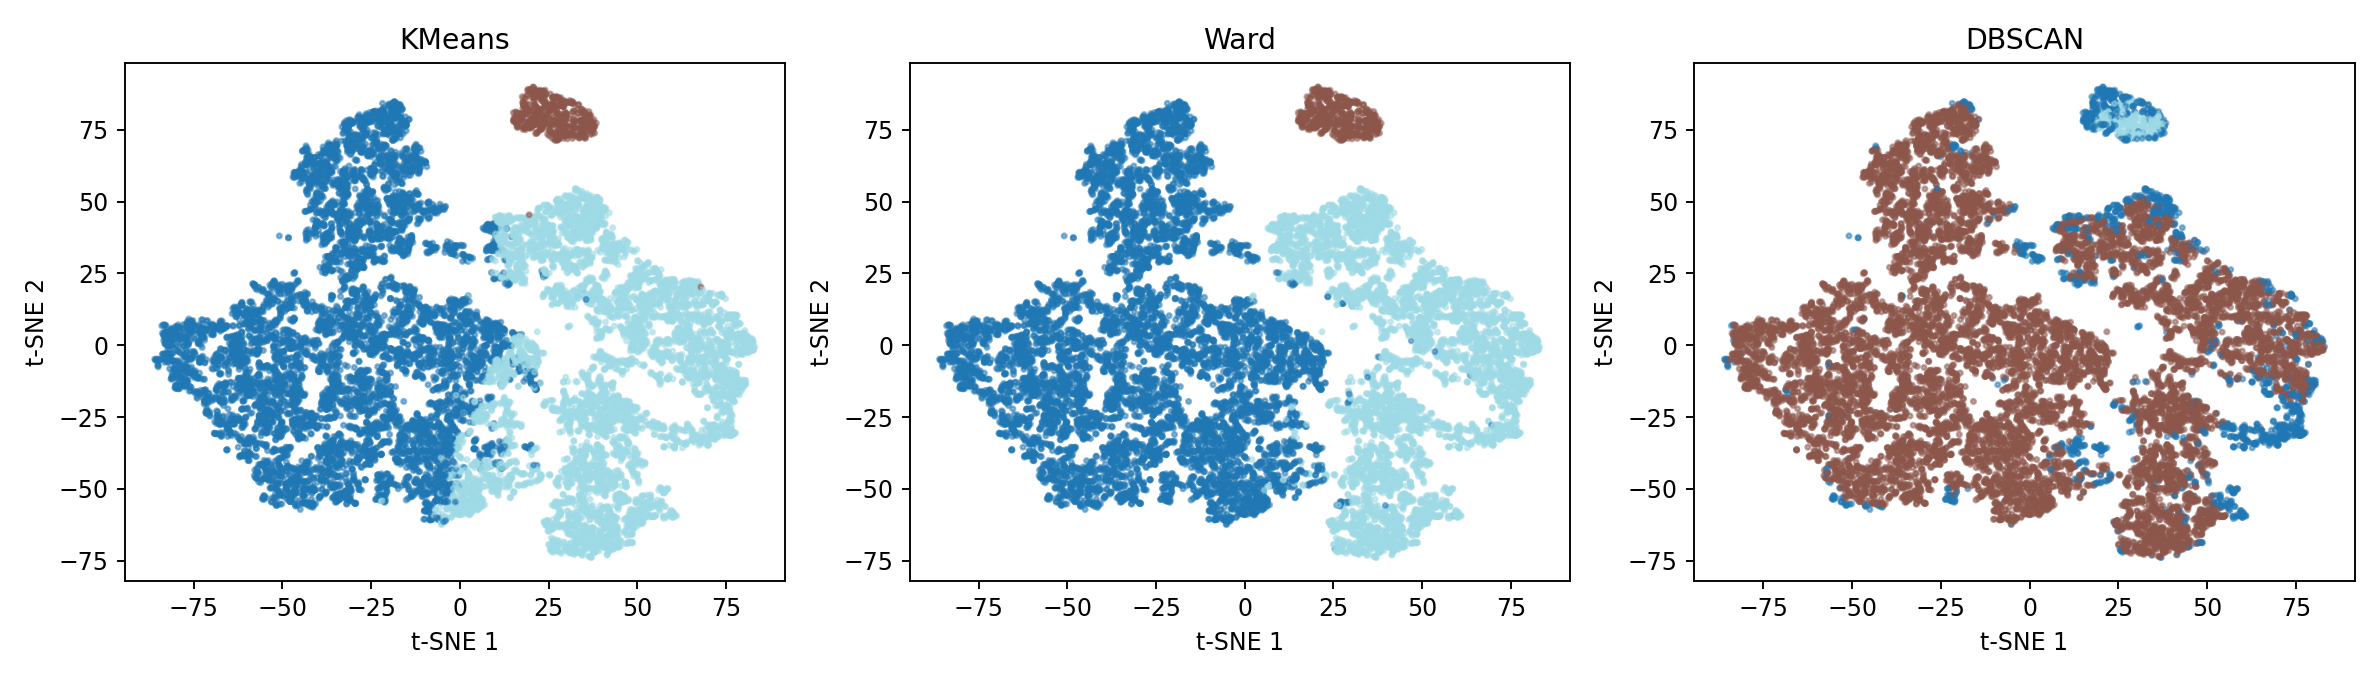

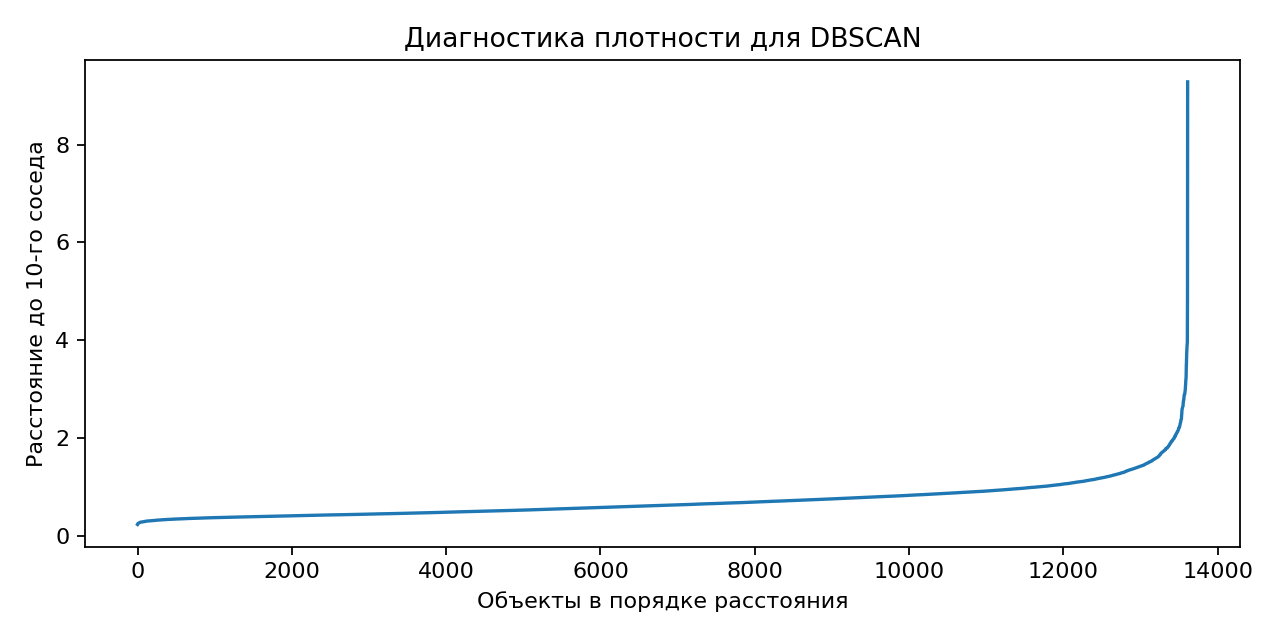

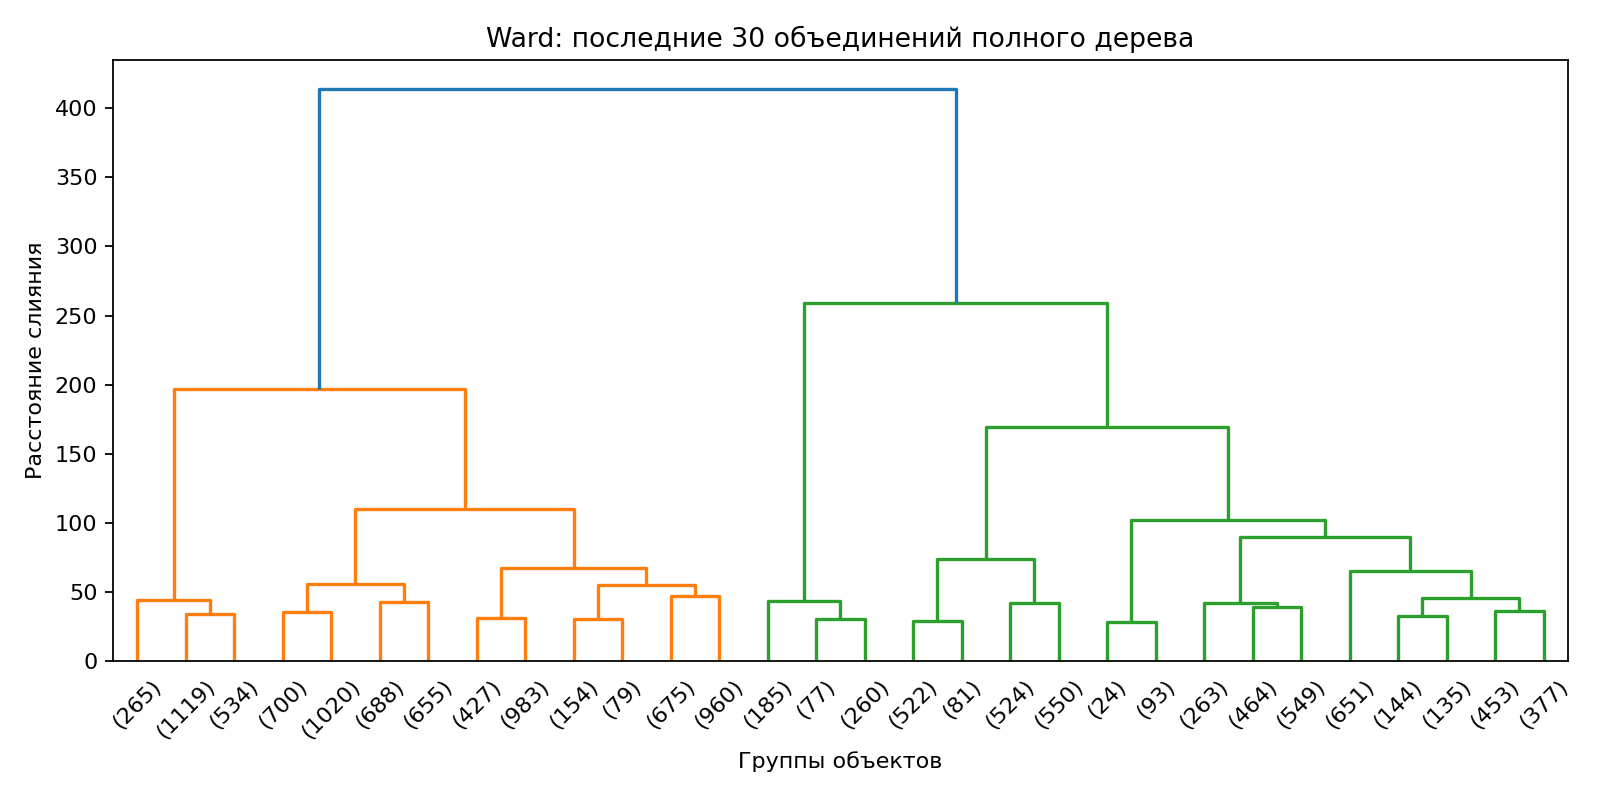

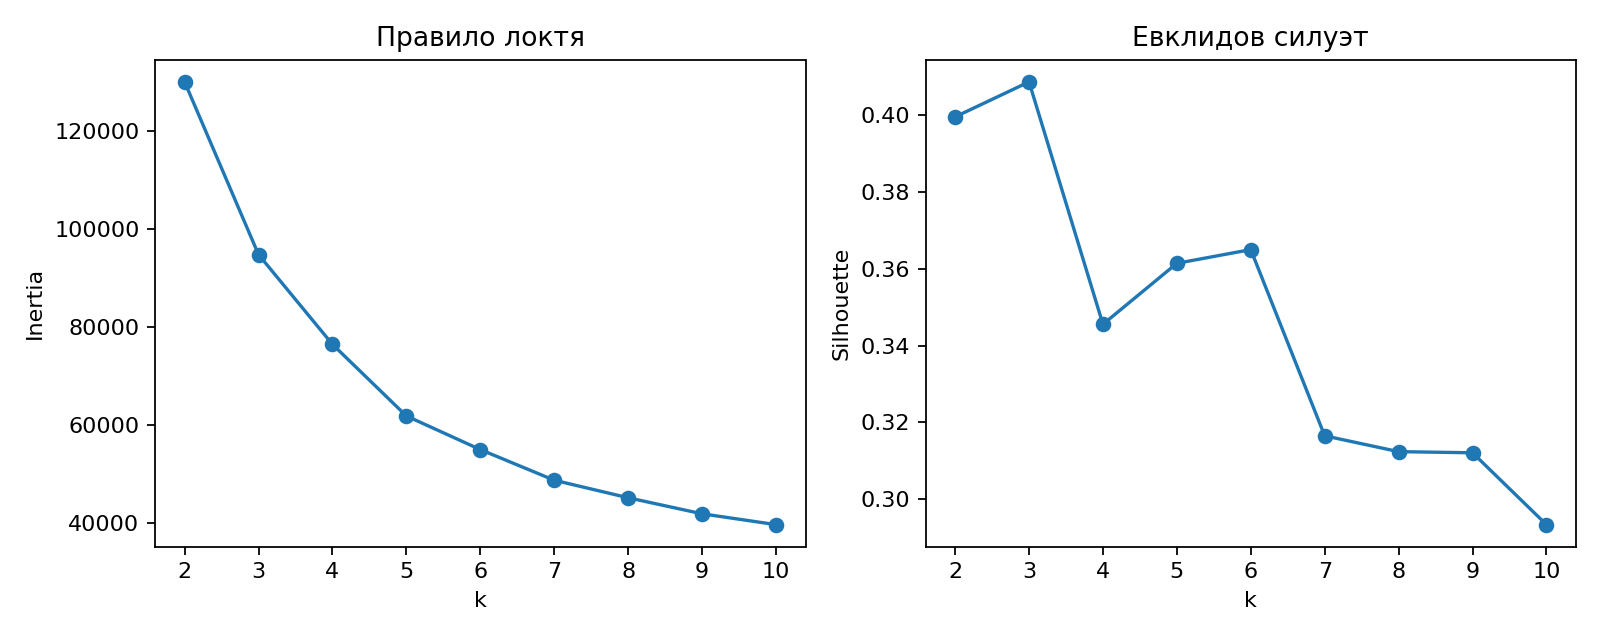

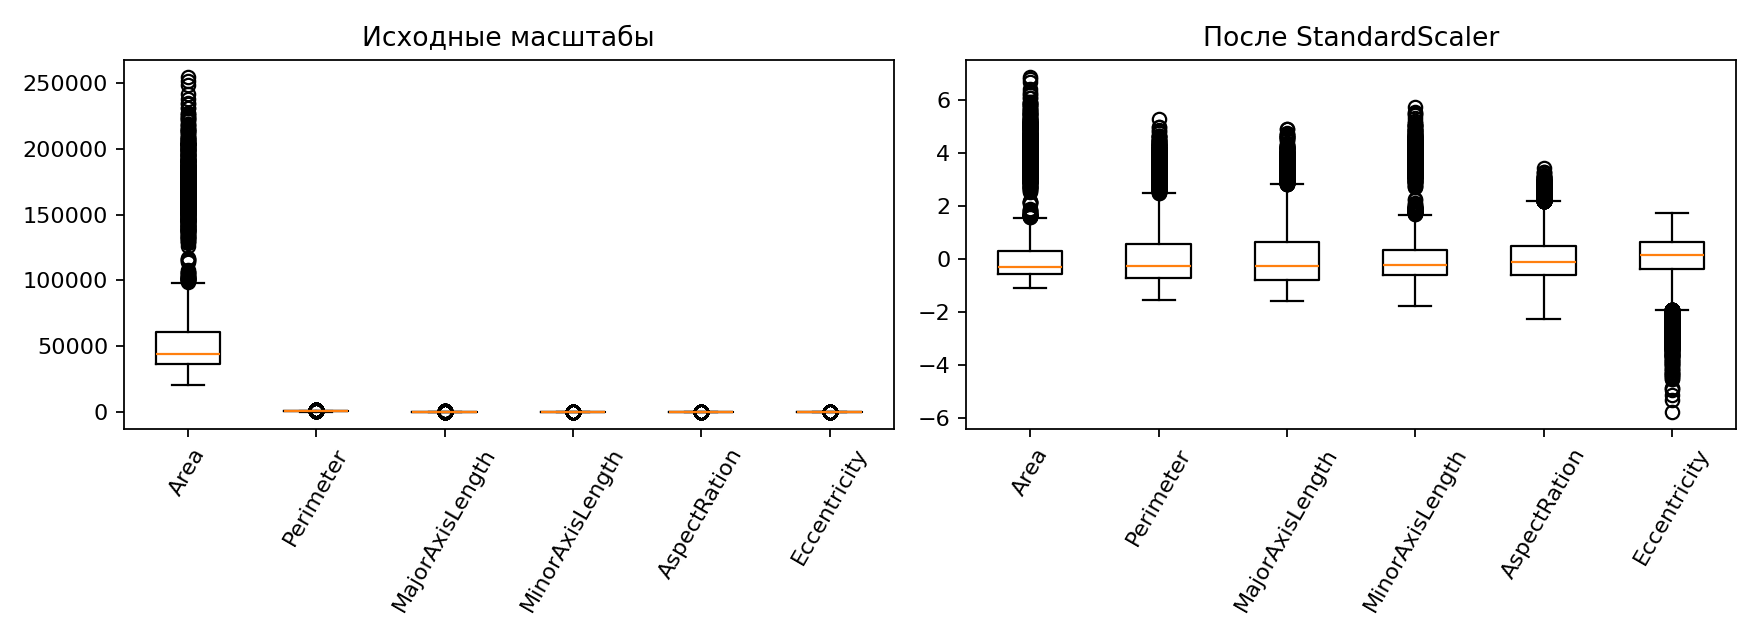

In [6]:
start=perf_counter();embedding=TSNE(n_components=2,perplexity=40,init='pca',learning_rate='auto',random_state=SEED,max_iter=1000,n_jobs=2).fit_transform(X);tsne_s=perf_counter()-start
labels_by={'KMeans':km.labels_,'Ward':hier,'DBSCAN':db.labels_}
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(name,labels) in zip(axes,labels_by.items()):
    ax.scatter(embedding[:,0],embedding[:,1],c=labels,cmap='tab20',s=4,alpha=.5);ax.set(title=name,xlabel='t-SNE 1',ylabel='t-SNE 2')
fig.tight_layout();fig.savefig(OUT/'clusters_tsne.png',dpi=170);plt.show();plt.close(fig)
assign=pd.DataFrame({'row_id':np.arange(1,len(raw)+1),'reference_class':raw['Class'],'tsne1':embedding[:,0],'tsne2':embedding[:,1],**labels_by})
assign.to_csv(OUT/'assignments.csv',index=False)
profiles={};comparison=[]
for name,labels in labels_by.items():
    frame=raw[features].copy();frame['cluster']=labels
    profile=frame.groupby('cluster').agg(['mean','count']);profile.columns=['_'.join(c) for c in profile.columns];profile.to_csv(OUT/(name.lower()+'_profiles.csv'))
    profiles[name]=frame.groupby('cluster')[features].mean().round(5).reset_index().to_dict('records')
    comparison.append({'algorithm':name,'clusters':len(set(labels)-{-1}),'noise':int(np.sum(labels<0)),'coverage':float(np.mean(labels>=0)),'silhouette':sil(labels),'ARI_reference':float(adjusted_rand_score(raw['Class'],labels)),'NMI_reference':float(normalized_mutual_info_score(raw['Class'],labels))})
pd.DataFrame(comparison).to_csv(OUT/'comparison.csv',index=False);print(pd.DataFrame(comparison).to_string(index=False))
joblib.dump({'scaler':scaler,'features':features,'kmeans':km,'ward_linkage':tree,'dbscan':db},MODELS/'clustering.joblib')
loaded=joblib.load(MODELS/'clustering.joblib');assert np.array_equal(loaded['kmeans'].predict(loaded['scaler'].transform(X_raw)),km.labels_)
summary={'environment':{'python':platform.python_version(),'sklearn':sklearn.__version__,'cpus':os.cpu_count()},'source_sha256':hashlib.sha256(data_path.read_bytes()).hexdigest(),'quality':quality,'scaler_mean':scaler.mean_.tolist(),'scaler_scale':scaler.scale_.tolist(),'sample_size':len(sample),'sample_row_ids':(sample+1).tolist(),'kmeans':k_rows,'selected_k':BEST_K,'hierarchy':{'rows':len(X),'merges':len(tree),'fit_s':hier_s},'dbscan_grid':db_rows,'selected_dbscan':best_db,'comparison':comparison,'profiles':profiles,'tsne':{'rows':len(X),'perplexity':40,'iterations':1000,'seconds':tsne_s},'roundtrip_equal':True}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
print('All clustering assignments:',len(assign))
from IPython.display import display, Image as DisplayImage
for saved_plot in sorted(OUT.glob('*.png')):
    display(DisplayImage(filename=str(saved_plot)))